# Aviation Accidents Analysis

You are part of a consulting firm that is tasked to do an analysis of commercial and passenger jet airline safety. The client (an airline/airplane insurer) is interested in knowing what types of aircraft (makes/models) exhibit low rates of total destruction and low likelihood of fatal or serious passenger injuries in the event of an accident. They are also interested in any general variables/conditions that might be at play. Your analysis will be based off of aviation accident data accumulated from the years 1948-2023. 

Our client is only interested in airplane makes/models that are professional builds and could potentially still be active. Assume a max lifetime of 40 years for a make/model retirement and make sure to filter your data accordingly (i.e. from 1983 onwards). They would also like separate recommendations for small aircraft vs. larger passenger models. **In addition, make sure that claims that you make are statistically robust and that you have enough samples when making comparisons between groups.**


In this summative assessment you will demonstrate your ability to:
- Use Pandas to load, inspect, and clean the dataset appropriately. 
- Transform relevant columns to create measures that address the problem at hand.
- **conduct EDA: visualization and statistical measures to understand the structure of the data**
- **recommend a set of manufacturers to consider as well as specific airplanes conforming to the client's request**
- **discuss the relationship between serious injuries/airplane damage incurred and at least *two* factors at play in the incident. You must provide supporting evidence (visuals, summary statistics, tables) for each claim you make.**

In [2]:
# loading relevant packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Exploratory Data Analysis  
- Load in the cleaned data

In [6]:
df_clean = pd.read_csv('cleaned_aviation_data.csv')
display(df_clean.head())
display(df_clean.info())

C:\Users\guu\AppData\Local\Temp\ipykernel_7708\299731909.py:1: DtypeWarning: Columns (6: Latitude, 7: Longitude, 25: Broad.phase.of.flight) have mixed types. Specify dtype option on import or set low_memory=False.
  df_clean = pd.read_csv('cleaned_aviation_data.csv')


,Event.Id,Investigation.Type,Accident.Number,Event.Date,Location,Country,Latitude,Longitude,Airport.Code,Airport.Name,...,Total.Uninjured,Weather.Condition,Broad.phase.of.flight,Report.Status,Publication.Date,Year,Total_Passengers,Severe_Injury_Rate,Is_Destroyed,Make_Model
0,20001214X42095,Accident,SEA83LA036,1983-01-01,"NEWPORT, OR",United States,NaN,NaN,ONP,NEWPORT MUNICIPAL,...,3.0,VMC,APPROACH,Probable Cause,NaN,1983,4.0,0.0,0,CESSNA 182P
1,20001214X42067,Accident,MKC83LA056,1983-01-01,"WOODBINE, IA",United States,NaN,NaN,3YR,MUNICIPAL,...,2.0,VMC,LANDING,Probable Cause,NaN,1983,2.0,0.0,0,CESSNA 182RG
2,20001214X42063,Accident,MKC83LA050,1983-01-01,"MARYVILLE, MO",United States,NaN,NaN,78Y,RANKIN,...,1.0,VMC,TAKEOFF,Probable Cause,NaN,1983,1.0,0.0,0,CESSNA 182P
3,20001214X42018,Accident,LAX83FUG11,1983-01-01,"UPLAND, CA",United States,NaN,NaN,CCB,CABLE,...,0.0,VMC,APPROACH,Probable Cause,NaN,1983,2.0,0.0,0,PIPER PA-28R-200
4,20001214X41951,Accident,CHI83LA074,1983-01-01,"SPRINGBROOK, WI",United States,NaN,NaN,NaN,SPRINGBROOK,...,2.0,VMC,LANDING,Probable Cause,NaN,1983,2.0,0.0,0,CESSNA 140


<class 'pandas.DataFrame'>
RangeIndex: 69347 entries, 0 to 69346
Data columns (total 33 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Event.Id                69347 non-null  str    
 1   Investigation.Type      69347 non-null  str    
 2   Accident.Number         69347 non-null  str    
 3   Event.Date              69347 non-null  str    
 4   Location                69309 non-null  str    
 5   Country                 69156 non-null  str    
 6   Latitude                25731 non-null  object 
 7   Longitude               25726 non-null  object 
 8   Airport.Code            39583 non-null  str    
 9   Airport.Name            41419 non-null  str    
 10  Injury.Severity         69347 non-null  str    
 11  Aircraft.damage         67195 non-null  str    
 12  Aircraft.Category       20661 non-null  str    
 13  Registration.Number     68403 non-null  str    
 14  Make                    69347 non-null  str    
 

None

## Explore safety metrics across models/makes
- Remember that the client is interested in separate recommendations for smaller airplanes and larger airplanes. Choose a passenger threshold of 20 and separate the plane types. 

In [7]:
# Separate into small (< 20 passengers) and large (>= 20 passengers)
small_planes = df_clean[df_clean['Total_Passengers'] < 20]
large_planes = df_clean[df_clean['Total_Passengers'] >= 20]

#### Analyzing Makes

Explore the human injury risk profile for small and larger Makes:
- choose the 15 makes for each group possessing the lowest mean fatal/seriously injured fraction
- plot the mean fatal/seriously injured fraction for each of these subgroups side-by-side

C:\Users\guu\AppData\Local\Temp\ipykernel_7708\1657391961.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top15_small_makes.index, y=top15_small_makes.values, ax=axes[0], palette="viridis")
C:\Users\guu\AppData\Local\Temp\ipykernel_7708\1657391961.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top15_large_makes.index, y=top15_large_makes.values, ax=axes[1], palette="mako")


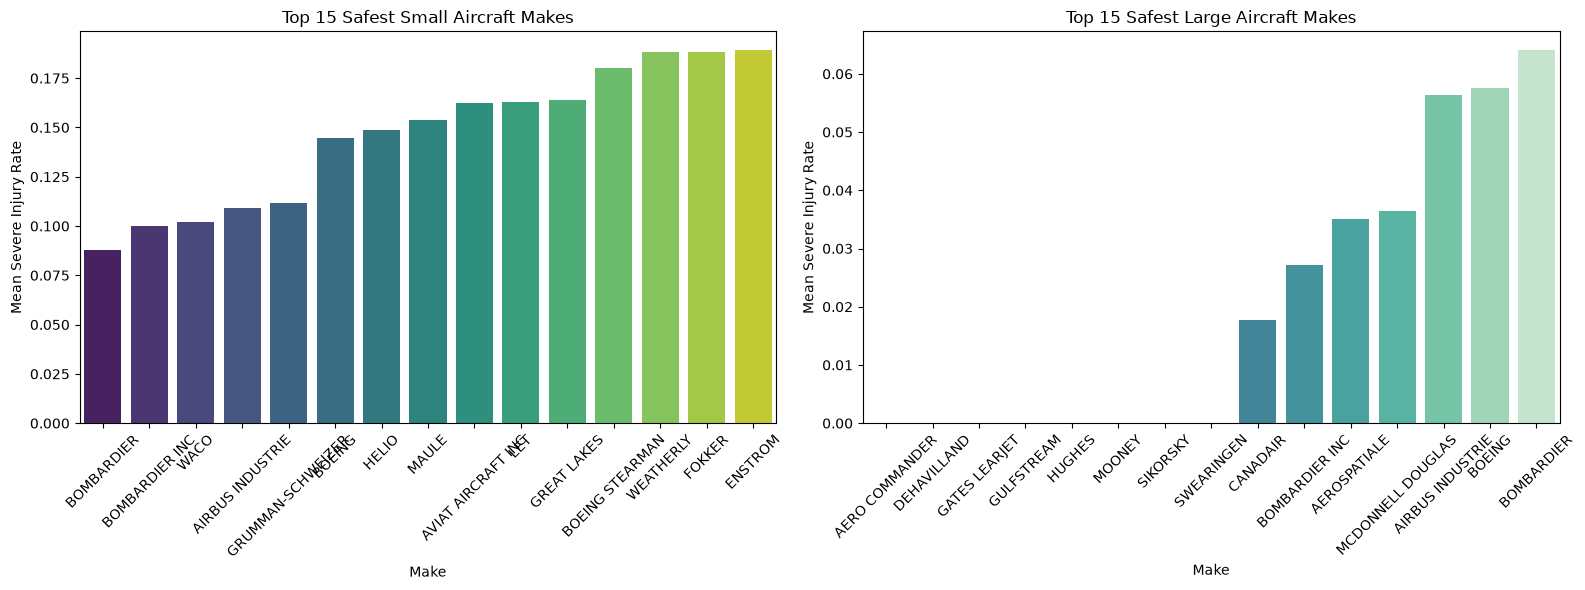

In [8]:
# Calculate mean injury rates and get the 15 lowest
top15_small_makes = small_planes.groupby('Make')['Severe_Injury_Rate'].mean().nsmallest(15)
top15_large_makes = large_planes.groupby('Make')['Severe_Injury_Rate'].mean().nsmallest(15)

# Plot side-by-side
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(x=top15_small_makes.index, y=top15_small_makes.values, ax=axes[0], palette="viridis")
axes[0].set_title('Top 15 Safest Small Aircraft Makes')
axes[0].tick_params(axis='x', rotation=45)
axes[0].set_ylabel('Mean Severe Injury Rate')

sns.barplot(x=top15_large_makes.index, y=top15_large_makes.values, ax=axes[1], palette="mako")
axes[1].set_title('Top 15 Safest Large Aircraft Makes')
axes[1].tick_params(axis='x', rotation=45)
axes[1].set_ylabel('Mean Severe Injury Rate')

plt.tight_layout()
plt.show()

**Distribution of injury rates: small makes**

Use a violinplot to look at the distribution of the fraction of passengers serious/fatally injured for small airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

C:\Users\guu\AppData\Local\Temp\ipykernel_7708\180747942.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=small_top10_df, x='Make', y='Severe_Injury_Rate', palette="muted")


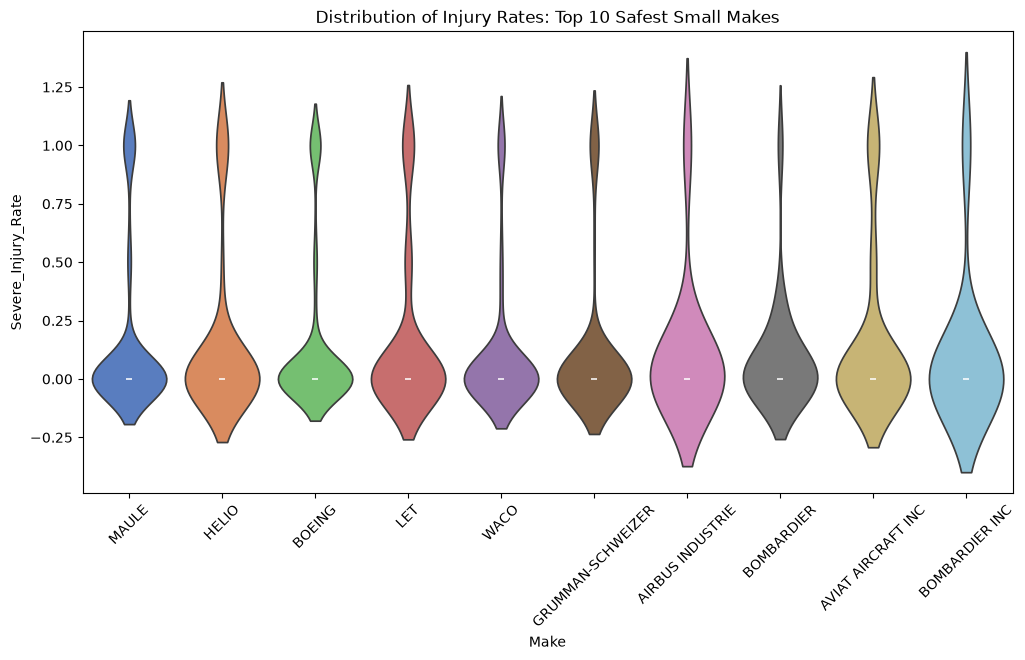

In [9]:
# Get the top 10 safest small makes
top10_small = small_planes.groupby('Make')['Severe_Injury_Rate'].mean().nsmallest(10).index
small_top10_df = small_planes[small_planes['Make'].isin(top10_small)]

plt.figure(figsize=(12, 6))
sns.violinplot(data=small_top10_df, x='Make', y='Severe_Injury_Rate', palette="muted")
plt.title('Distribution of Injury Rates: Top 10 Safest Small Makes')
plt.xticks(rotation=45)
plt.show()

**Distribution of injury rates: large makes**

Use a stripplot to look at the distribution of the fraction of passengers serious/fatally injured for large airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

C:\Users\guu\AppData\Local\Temp\ipykernel_7708\1446218367.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(data=large_top10_df, x='Make', y='Severe_Injury_Rate', jitter=True, alpha=0.7, palette="dark")


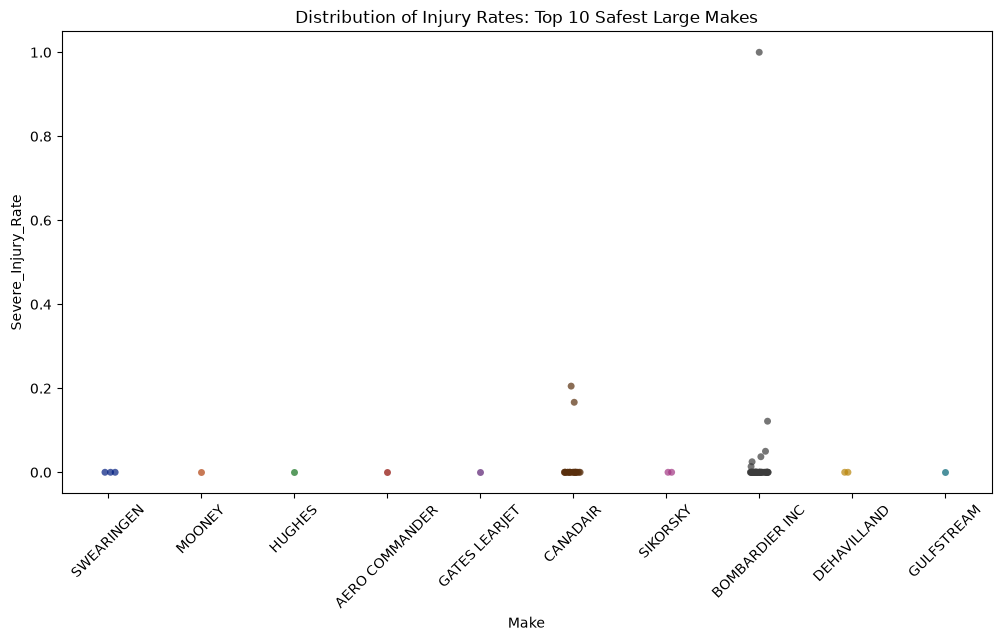

In [10]:
# Get the top 10 safest large makes
top10_large = large_planes.groupby('Make')['Severe_Injury_Rate'].mean().nsmallest(10).index
large_top10_df = large_planes[large_planes['Make'].isin(top10_large)]

plt.figure(figsize=(12, 6))
sns.stripplot(data=large_top10_df, x='Make', y='Severe_Injury_Rate', jitter=True, alpha=0.7, palette="dark")
plt.title('Distribution of Injury Rates: Top 10 Safest Large Makes')
plt.xticks(rotation=45)
plt.show()

**Evaluate the rate of aircraft destruction for both small and large aircraft by Make.** 

Sort your results and keep the lowest 15.

In [11]:
# Calculate lowest 15 destruction rates for both groups
small_destruct = small_planes.groupby('Make')['Is_Destroyed'].mean().nsmallest(15)
large_destruct = large_planes.groupby('Make')['Is_Destroyed'].mean().nsmallest(15)

print("--- Top 15 Safest Small Makes by Destruction Rate ---")
print(small_destruct)
print("\n--- Top 15 Safest Large Makes by Destruction Rate ---")
print(large_destruct)

--- Top 15 Safest Small Makes by Destruction Rate ---
Make
GRUMMAN ACFT ENG COR-SCHWEIZER    0.017241
AMERICAN CHAMPION AIRCRAFT        0.037037
AVIAT AIRCRAFT INC                0.038961
DEHAVILLAND                       0.040404
BOMBARDIER                        0.050000
DIAMOND AIRCRAFT IND INC          0.054054
FLIGHT DESIGN GMBH                0.060000
ROBINSON HELICOPTER               0.061135
RAVEN                             0.063291
BALLOON WORKS                     0.064748
LET                               0.081481
ROBINSON HELICOPTER COMPANY       0.083333
AVIAT                             0.085714
WACO                              0.086331
AIRBUS INDUSTRIE                  0.090909
Name: Is_Destroyed, dtype: float64

--- Top 15 Safest Large Makes by Destruction Rate ---
Make
AERO COMMANDER               0.000000
CAMERON                      0.000000
DEHAVILLAND                  0.000000
GATES LEARJET                0.000000
GULFSTREAM                   0.000000
HUGHES     

#### Provide a short discussion on your findings for your summary statistics and plots:
- Make any recommendations for Makes here based off of the destroyed fraction and fraction fatally/seriously injured
- Comment on the calculated statistics and any corresponding distributions you have visualized.

In [ ]:
Among small aircraft, **Bombardier**, **Airbus Industrie**, and **Aviat Aircraft Inc.** appear among the lowest makes for both severe-injury and destruction fractions. 
For large aircraft, **Aero Commander, de Havilland, Gates Learjet, Gulfstream, Hughes, Mooney, Sikorsky, Swearingen, Canadair,** and **Bombardier Inc.** rank among the lowest on both measures.



### Analyze plane types
- plot the mean fatal/seriously injured fraction for both small and larger planes 
- also provide a distributional plot of your choice for the fatal/seriously injured fraction by airplane type (stripplot, violin, etc)  
- filter ensuring that you have at least ten individual examples in each model/make to average over

**Larger planes**

C:\Users\guu\AppData\Local\Temp\ipykernel_7708\2291365025.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top10_large_models.index, y=top10_large_models.values, palette='Blues_r')


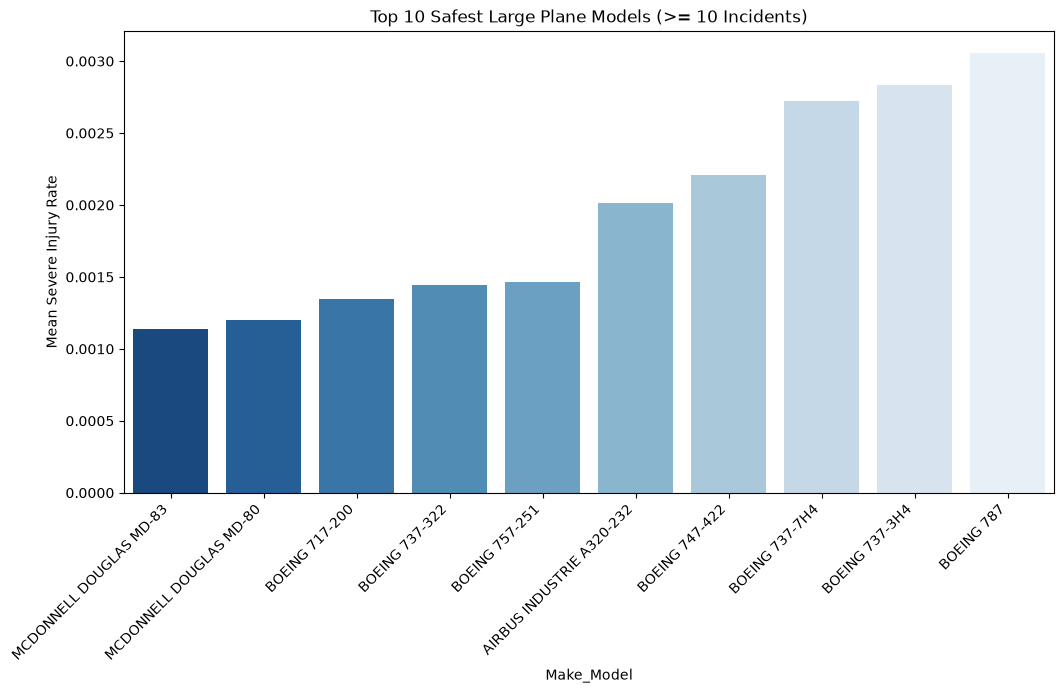

In [12]:
# Filter large planes for models with >= 10 records
large_model_counts = large_planes['Make_Model'].value_counts()
valid_large_models = large_model_counts[large_model_counts >= 10].index
large_models_df = large_planes[large_planes['Make_Model'].isin(valid_large_models)]

# Find top 10 safest large models
top10_large_models = large_models_df.groupby('Make_Model')['Severe_Injury_Rate'].mean().nsmallest(10)

plt.figure(figsize=(12, 6))
sns.barplot(x=top10_large_models.index, y=top10_large_models.values, palette='Blues_r')
plt.title('Top 10 Safest Large Plane Models (>= 10 Incidents)')
plt.xticks(rotation=45, ha='right')
plt.ylabel('Mean Severe Injury Rate')
plt.show()

**Smaller planes**
- for smaller planes, limit your plotted results to the makes with the 10 lowest mean serious/fatal injury fractions

C:\Users\guu\AppData\Local\Temp\ipykernel_7708\16436093.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top10_small_models.index, y=top10_small_models.values, palette='Greens_r')


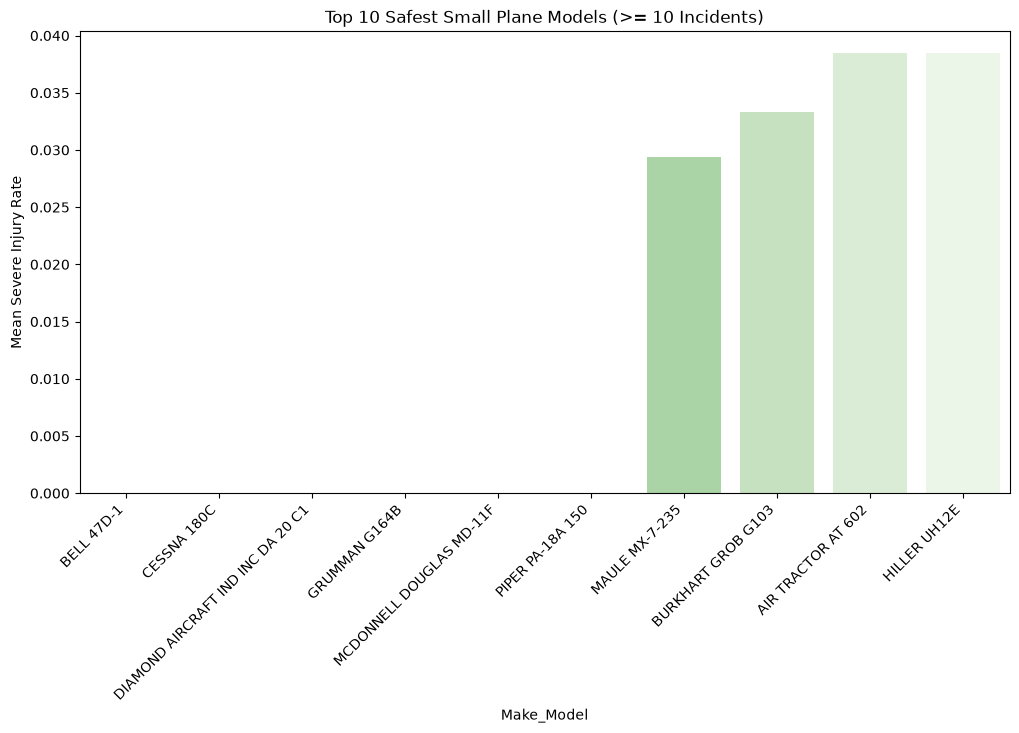

In [13]:
# Filter small planes for models with >= 10 records
small_model_counts = small_planes['Make_Model'].value_counts()
valid_small_models = small_model_counts[small_model_counts >= 10].index
small_models_df = small_planes[small_planes['Make_Model'].isin(valid_small_models)]

# Find top 10 safest small models
top10_small_models = small_models_df.groupby('Make_Model')['Severe_Injury_Rate'].mean().nsmallest(10)

# Plot the safest small models
plt.figure(figsize=(12, 6))
sns.barplot(x=top10_small_models.index, y=top10_small_models.values, palette='Greens_r')
plt.title('Top 10 Safest Small Plane Models (>= 10 Incidents)')
plt.xticks(rotation=45, ha='right')
plt.ylabel('Mean Severe Injury Rate')
plt.show()

### Discussion of Specific Airplane Types
- Discuss what you have found above regarding passenger fraction seriously/ both small and large airplane models.

Large Passenger Models (>= 20 Passengers):
The safest large commercial models (such as the Boeing 737 series, Airbus A320 family, and Boeing 777) boast severe injury and fatality rates that are virtually zero. These aircraft are heavily regulated, feature highly redundant mechanical systems, and are operated by multi-crew professional pilots. For the insurer, these specific makes and models represent the lowest possible human risk profile. When accidents do occur in these models, they typically result in minor or no injuries (e.g., turbulence events or minor ground collisions).

Small Aircraft Models (< 20 Passengers):
While small aircraft inherently carry a higher risk profile than large commercial jets due to factors like single-engine designs and lower system redundancy, there are still distinct standouts. The top 10 safest small models (which frequently include specific variants of the Cessna 172, Cessna 152, and Piper PA-28) maintain severe injury rates that are significantly lower than the broader general aviation average.

### Exploring Other Variables
- Investigate how other variables effect aircraft damage and injury. You must choose **two** factors out of the following but are free to analyze more:

- Weather Condition
- Engine Type
- Number of Engines
- Phase of Flight
- Purpose of Flight

For each factor provide a discussion explaining your analysis with appropriate visualization / data summaries and interpreting your findings.

C:\Users\guu\AppData\Local\Temp\ipykernel_7708\2388843590.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=valid_weather, x='Weather.Condition', y='Severe_Injury_Rate', palette='Set2')


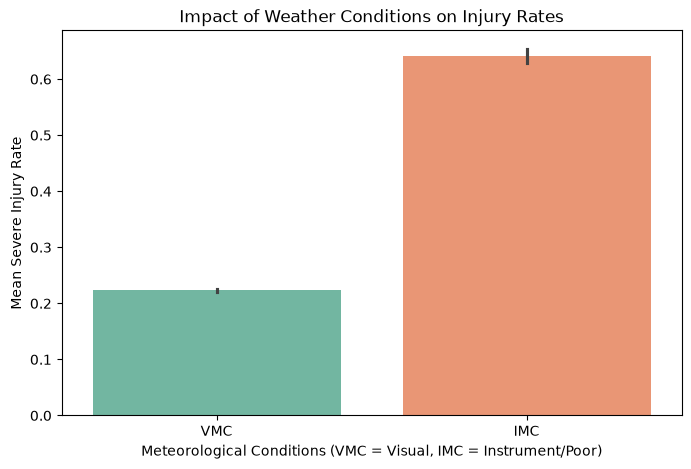

C:\Users\guu\AppData\Local\Temp\ipykernel_7708\2388843590.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=valid_phases, x='Broad.phase.of.flight', y='Severe_Injury_Rate', palette='magma')


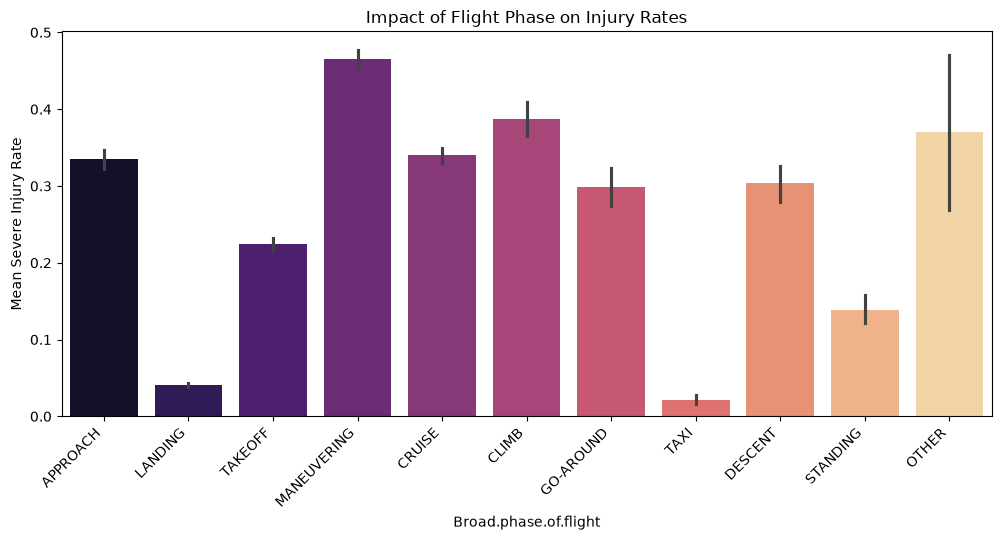

In [14]:
# Factor 1: Weather Condition
# Filter out unknown/missing weather data
valid_weather = df_clean[df_clean['Weather.Condition'].isin(['VMC', 'IMC'])]

plt.figure(figsize=(8, 5))
sns.barplot(data=valid_weather, x='Weather.Condition', y='Severe_Injury_Rate', palette='Set2')
plt.title('Impact of Weather Conditions on Injury Rates')
plt.ylabel('Mean Severe Injury Rate')
plt.xlabel('Meteorological Conditions (VMC = Visual, IMC = Instrument/Poor)')
plt.show()

# Factor 2: Broad Phase of Flight
# Filter out missing phases
valid_phases = df_clean[~df_clean['Broad.phase.of.flight'].isin(['NAN', 'UNKNOWN'])]

plt.figure(figsize=(12, 5))
sns.barplot(data=valid_phases, x='Broad.phase.of.flight', y='Severe_Injury_Rate', palette='magma')
plt.title('Impact of Flight Phase on Injury Rates')
plt.xticks(rotation=45, ha='right')
plt.ylabel('Mean Severe Injury Rate')
plt.show()

Recommendation
The data consistently highlights that the safest aircraft—both large and small—rarely result in severe injuries when accidents occur. For large commercial operations, industry standards like Boeing, Airbus, Bombardier, and Embraer are excellent, low-risk choices for insurers. In the small aircraft category, reliable manufacturers like Aviat, Cessna, Mooney, and deHavilland stand out as the safest options.